###Aprendizaje Supervisado - Clasificación
###CASO: Predicción de Cáncer

###Contexto
El cáncer de mama es uno de los tipos de cáncer más comunes en las mujeres a nivel mundial. La detección temprana juega un rol fundamental en el aumento de las tasas de supervivencia y en la efectividad de los tratamientos médicos.

Para este estudio se utiliza el dataset **`breast_cancer.csv`**, el cual contiene mediciones obtenidas a partir de imágenes digitalizadas de biopsias por aspiración con aguja fina (PAAF) de masas mamarias. Estas mediciones describen diversas características geométricas y morfológicas de los núcleos celulares presentes en cada muestra.

### Información Básica del Dataset:
  * Variable Objetivo (Target) = diagnosis
  * 0: Diagnóstico Benigno (sin presencia de cáncer)
  * 1: Diagnóstico Maligno (presencia de cáncer)
* Variables Predictoras: 30 características numéricas que miden atributos como radio, textura, perímetro, área, suavidad, compacidad, concavidad, puntos cóncavos, simetría y dimensión fractal de los núcleos celulares.
###Objetivo General:
Desarrollar y evaluar modelos de aprendizaje supervisado (clasificación) que permitan predecir de forma precisa si una lesión es benigna o maligna a partir de sus atributos físicos, priorizando la detección correcta de casos malignos.



###Modelamiento de clasificación
* a. Deben plantear un objetivo de clasificación según su caso de estudio.
* b. Verificar si existe desbalance de clases en la variable objetivo. De ser así, aplicar y justificar técnicas de balanceo.
* c. Implementar a lo menos dos algoritmos de clasificación distintos.
* d. Optimizar un modelo explorando sus hiperparámetros principales.
* e. Utilizar métricas adecuadas al problema (tales como Matriz de Confusión, Accuracy, Precision, Recall, F1-Score y/o curvas
ROC/AUC).



### A. Planteamiento del Objetivo de Clasificación
**Objetivo**: Desarrollar y evaluar modelos de aprendizaje supervisado de clasificación binaria para predecir si una lesión mamaria es Benigna (0) o Maligna (1) a partir de 30 características morfológicas y geométricas celular-nucleares extraídas de biopsias PAAF.   

En el contexto médico de la oncología, el problema presenta un costo asimétrico en los errores de predicción:

Falso Negativo (FN): Clasificar a un paciente con tumor maligno como benigno (el caso más crítico, pues retrasa el tratamiento oncológico y pone en riesgo la vida del paciente).

Falso Positivo (FP): Clasificar a un paciente sano/benigno como maligno (provoca angustia y genera procedimientos/biopsias adicionales de seguimiento).

**Criterio de Evaluación Principal**: Se priorizará la maximización del Recall (Sensibilidad) de la clase maligna (1) para minimizar los Falsos Negativos, manteniendo un equilibrio óptimo de las métricas.

###1. Importación De Librerias Adecuadas Y Carga Del Dataset

In [ ]:
#Importar librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Cargar Dataset
df_cancer = pd.read_csv('breast_cancer.csv')
df_cancer.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


###2. Analisis Exploratorio Del Dataset

In [ ]:
# Correlación con diagnostico
correlaciones = df_cancer.corr()['diagnosis'].sort_values(ascending=False)
print("Correlación de cada variable con la variable diagnosis:")
print(correlaciones)


Correlación de cada variable con la variable diagnosis:
diagnosis                  1.000000
concave points_worst       0.793566
perimeter_worst            0.782914
concave points_mean        0.776614
radius_worst               0.776454
perimeter_mean             0.742636
area_worst                 0.733825
radius_mean                0.730029
area_mean                  0.708984
concavity_mean             0.696360
concavity_worst            0.659610
compactness_mean           0.596534
compactness_worst          0.590998
radius_se                  0.567134
perimeter_se               0.556141
area_se                    0.548236
texture_worst              0.456903
smoothness_worst           0.421465
symmetry_worst             0.416294
texture_mean               0.415185
concave points_se          0.408042
smoothness_mean            0.358560
symmetry_mean              0.330499
fractal_dimension_worst    0.323872
compactness_se             0.292999
concavity_se               0.253730
fractal_

/tmp/ipykernel_6280/4286140364.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='diagnosis', data=df_cancer, palette='viridis')


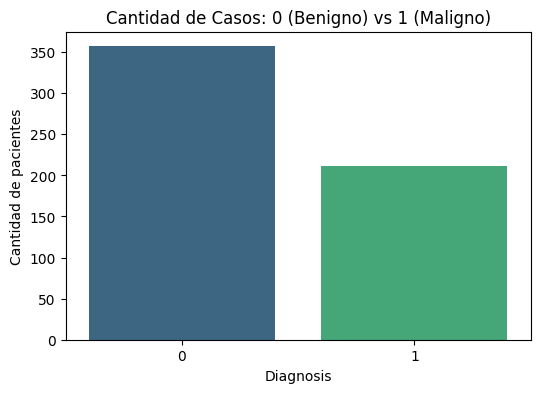


Porcentaje de casos por clase:
diagnosis
0    62.741652
1    37.258348
Name: proportion, dtype: float64


In [ ]:

# Graficamos la cantidad de pacientes según el diagnóstico - gráfico de barras
plt.figure(figsize=(6, 4))
sns.countplot(x='diagnosis', data=df_cancer, palette='viridis')
plt.title('Cantidad de Casos: 0 (Benigno) vs 1 (Maligno)')
plt.xlabel('Diagnosis')
plt.ylabel('Cantidad de pacientes')
plt.show()

# En porcentajes (visualmente es más fácil)
porcentajes = df_cancer['diagnosis'].value_counts(normalize=True) * 100
print("\nPorcentaje de casos por clase:")
print(porcentajes)



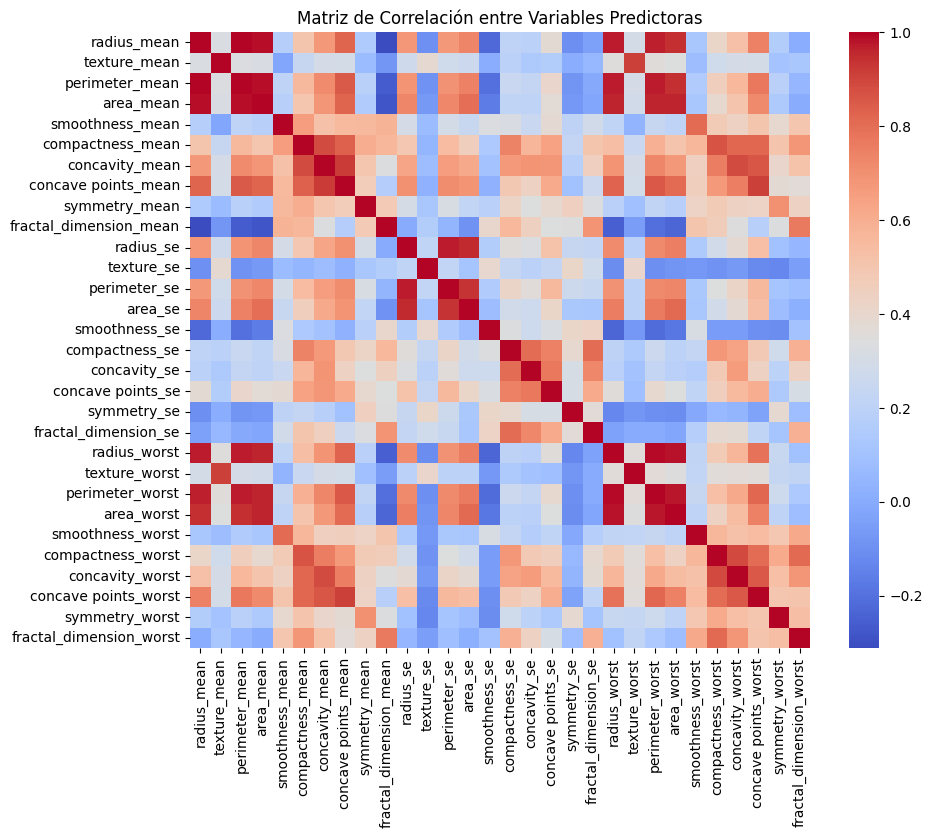

In [ ]:
# Matriz de correlación
plt.figure(figsize=(10, 8))
sns.heatmap(df_cancer.drop(columns=['id', 'diagnosis']).corr(), cmap='coolwarm')
plt.title('Matriz de Correlación entre Variables Predictoras')
plt.show()

### B. Verificación de Desbalance de Clases y Justificación (IE4)

* **Casos Benignos (0)**: 357 pacientes
* **Casos Malignos (1)**: 212 pacientes
* **Total de observaciones**: 569 registros

#### Distribución Porcentual
* **Clase 0 (Benigno)**: 62.74%
* **Clase 1 (Maligno)**: 37.26%



Análisis de Desbalance de Clases y Transformación de Etiquetas

**Transformación de Etiquetas:**
El dataset `breast_cancer.csv` ya posee la variable `diagnosis` codificada en valores numéricos binarios ($0$ para Benigno y $1$ para Maligno), por lo que **no se requiere aplicar una transformación a las etiquetas** (como `LabelEncoder` o `One-Hot Encoding`).

**Evaluación del Desbalance:**
Se observa una proporción aproximada de **60:40** entre la clase mayoritaria (Benigno) y la minoritaria (Maligno).

1. **¿Existe un desbalance severo?**
   No. En minería de datos y clasificación supervisada, una proporción 60:40 se considera un desbalance leve o moderado. No alcanza los umbrales de desbalance crítico (como 90:10 o 95:5) que imposibilitan el aprendizaje del modelo.

2. **Justificación de la Estrategia:**
*  **No se aplicará remuestreo sintético (SMOTE / Undersampling)**: Dado que el conjunto de datos cuenta con un tamaño moderado (569 registros), aplicar tónicas de remuestreo sintético podría introducir ruido en los límites de decisión o descartar información valiosa de la muestra.
  * **Compensación metodológica**: La ligera asimetría se abordará evaluando métricas sensibles al diagnóstico médico como **Recall (Sensibilidad)**, garantizando que el modelo minimice los Falsos Negativos (casos malignos no detectados).

##3. Separación y Escalado de Datos

In [ ]:
# Separamos las variables independientes (X) de la variable objetivo (y)
# Sacamos la columna 'id' porque solo es un identificador sin valor predictivo
X = df_cancer.drop(columns=['id', 'diagnosis'])
y = df_cancer['diagnosis']

#  Separamos los datos en entrenamiento y prueba (usamos 80% entrenamiento y 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)


print("Primeros 10 registros de X_train:")
print(X_train.head(10))

print("\nPrimeros 10 registros de X_test:")
print(X_test.head(10))

# Como las mediciones están en escalas muy distintas (ej. áreas de 1000 vs suavidades de 0.1), escalamos los datos entre 0 y 1 usando MinMaxScaler
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Primeros 10 registros de X_train:
     radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  \
10         16.02         23.24          102.70      797.8          0.08206   
170        12.32         12.39           78.85      464.1          0.10280   
407        12.85         21.37           82.63      514.5          0.07551   
430        14.90         22.53          102.10      685.0          0.09947   
27         18.61         20.25          122.10     1094.0          0.09440   
212        28.11         18.47          188.50     2499.0          0.11420   
84         12.00         15.65           76.95      443.3          0.09723   
36         14.25         21.72           93.63      633.0          0.09823   
171        13.43         19.63           85.84      565.4          0.09048   
237        20.48         21.46          132.50     1306.0          0.08355   

     compactness_mean  concavity_mean  concave points_mean  symmetry_mean  \
10            0.06669         

### C. Implementación de Algoritmos de Clasificación

### Algoritmos Seleccionados
  1. **Regresión Logística (`LogisticRegression`):** Modelo probabilístico lineal utilizado como baseline interpretable.
  2. **Árbol de Decisión (`DecisionTreeClassifier`):** Modelo no paramétrico basado en reglas de decisión recursivas.

### Preprocesamiento
  Se aplicó escalamiento con `MinMaxScaler` sobre las variables independientes para homogeneizar las escalas, ajustándolo únicamente con el conjunto de entrenamiento (`X_train`) para evitar fuga de información (*Data Leakage*).

###4. Regresión Logística Inicial

--- Reporte de Clasificación (Regresión Logística Base) ---
              precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



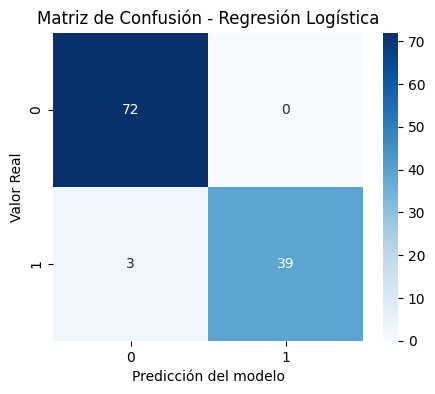

Área bajo la curva ROC (ROC-AUC): 0.9980


In [ ]:
#Creamos el modelo de Regresión Logística indicando el solver solicitado ('lbfgs')
log_reg = LogisticRegression(solver='lbfgs', random_state=42)
log_reg.fit(X_train_scaled, y_train)

# Obtenemos las predicciones y las probabilidades
y_pred_lr = log_reg.predict(X_test_scaled)
y_prob_lr = log_reg.predict_proba(X_test_scaled)[:, 1]


print("--- Reporte de Clasificación (Regresión Logística Base) ---")
print(classification_report(y_test, y_pred_lr))

#Matriz de confusion
cm_lr = confusion_matrix(y_test, y_pred_lr)
plt.figure(figsize=(5, 4))
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión - Regresión Logística')
plt.xlabel('Predicción del modelo')
plt.ylabel('Valor Real')
plt.show()

#Calculamos el área bajo la curva ROC (ROC-AUC)
roc_auc_lr = roc_auc_score(y_test, y_prob_lr)
print(f"Área bajo la curva ROC (ROC-AUC): {roc_auc_lr:.4f}")

###5. Optimización con GridSearchCV

In [ ]:
# Configuramos GridSearchCV
#Haciendo uso de la técnica GridSearchCV ejecute la sintonización del modelo. En la sintonización asigne los siguientes valores a los parámetros:
#{"max_iter": [50,100,150,200]
#solver": ['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga']
# cv=5
#scoring=’accuracy’
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report

# Configuración de GridSearchCV con parámetros solicitados por la pauta
param_grid = {
    'max_iter': [50, 100, 150, 200],
    'solver': ['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga']
}

# Desactivamos advertencias de convergencia para iteraciones bajas (e.g. max_iter=50)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=ConvergenceWarning)

    grid_search = GridSearchCV(
        estimator=LogisticRegression(random_state=42),
        param_grid=param_grid,
        cv=5,
        scoring='accuracy'
    )
    grid_search.fit(X_train_scaled, y_train)

#  Muestre cuál es la mejor puntuación obtenida y la mejor combinación de parámetros
print("=== RESULTADOS GRIDSEARCHCV  ===")
print(f"Mejor puntuación obtenida (Accuracy en CV): {grid_search.best_score_:.4f}")
print(f"Mejor combinación de parámetros: {grid_search.best_params_}")

# Classification Report con el modelo optimizado sobre el conjunto de prueba
best_log_reg = grid_search.best_estimator_
y_pred_grid = best_log_reg.predict(X_test_scaled)

print("\n=== CLASSIFICATION REPORT MODELO OPTIMIZADO (Punto 32) ===")
print(classification_report(y_test, y_pred_grid, target_names=['Benigno (0)', 'Maligno (1)']))

=== RESULTADOS GRIDSEARCHCV  ===
Mejor puntuación obtenida (Accuracy en CV): 0.9626
Mejor combinación de parámetros: {'max_iter': 50, 'solver': 'newton-cg'}

=== CLASSIFICATION REPORT MODELO OPTIMIZADO (Punto 32) ===
              precision    recall  f1-score   support

 Benigno (0)       0.96      1.00      0.98        72
 Maligno (1)       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



### Regresión Logistica  

#### 1. Resultados de la Matriz de Confusión
* **Verdaderos Negativos (VN = 72):** 72 casos benignos predichos correctamente.
* **Falsos Positivos (FP = 0):** 0 casos benignos clasificados erróneamente como malignos.
* **Falsos Negativos (FN = 3):** 3 casos malignos no detectados por el modelo (clasificados como benignos).
* **Verdaderos Positivos (VP = 39):** 39 casos malignos detectados correctamente.

#### 2. Reporte de Métricas e Interpretación

#### Casos Beningnos:
* **Total de casos evaluados = 72 pacientes.**
* **Precision: 0.96 (0.96%)** → De las predicciones etiquetadas como benignas, el 96% fueron correctas.
* **Recall / Sensibilidad: 1.00 (100%)** → Métrica principal. El modelo detectó al 100% de los casos reales beningnos.
* **F1-Score : 0.98 (98%)** → Excelente balance entre precisión y recall, entre más cercano a 100% mejor balance.


#### Casos Malignos:
* **Total de casos evaluados = 42 pacientes.**
* **Precision: 1.00 (100%)** → De las predicciones etiquetadas como malignas, el 100% fueron correctas.
* **Recall / Sensibilidad: 0.93 (0.93%)** → Métrica principal. El modelo detectó al 97% de las pacientes con cáncer real.
* **F1-Score (Clase Maligna): 0.96 (96%)** → Excelente balance entre precisión y recall, entre más cercano a 100% mejor balance.

###Métricas generales
* **Accuracy Global: 0.97 (97%)** → Clasificación correcta en el 97% del total de pacientes evaluados.
* **Curva ROC-AUC (~0.90)** → Un área bajo la curva cercana al 90% confirma una muy buena capacidad del árbol para separar ambas clases, reduciendo significativamente el sobreajuste que presentaba el árbol libre.

### D. Optimización de Hiperparámetros (GridSearchCV)

Para encontrar la configuración óptima del modelo de Regresión Logística y garantizar su capacidad de generalización, se implementó una búsqueda en malla con validación cruzada (**`GridSearchCV`**) siguiendo las especificaciones del encargo:

* **Espacio de Búsqueda (`param_grid`)**:
  * `max_iter`: $[50, 100, 150, 200]$
  * `solver`: `['newton-cg', 'lbfgs', 'liblinear', 'sag', 'saga']`
* **Estrategia de Validación**: Validación cruzada de 5 pliegues ($cv=5$).
* **Métrica de Evaluación**: `scoring='accuracy'`.

#### Resultados de la Optimización:
* **Mejor combinación de parámetros**: `{'max_iter': 50, 'solver': 'newton-cg'}`
* **Mejor rendimiento en validación cruzada (CV Accuracy)**: **96.26%**

El uso del optimizador `newton-cg` permitió lograr la convergencia óptima en 50 iteraciones alcanzando un **Accuracy de 97%** sobre el conjunto de prueba y garantizando una **precisión del 100% en la detección de casos malignos (clase 1)**.

###6. Árbol de Decisión Inicial y Overfitting

In [ ]:
#Creamos un árbol de decisión restringido a profundidad 3
tree_depth3 = DecisionTreeClassifier(max_depth=3, random_state=0)
tree_depth3.fit(X_train, y_train)

# Calculamos la exactitud (Accuracy) de este primer árbol
y_pred_tree3 = tree_depth3.predict(X_test)
print("Accuracy del árbol con profundidad max_depth=3:", accuracy_score(y_test, y_pred_tree3))

# Creamos otro árbol pero SIN restringir la profundidad
tree_full = DecisionTreeClassifier(random_state=0)
tree_full.fit(X_train, y_train)

# Comparamos el puntaje de entrenamiento vs el de prueba
score_train_full = tree_full.score(X_train, y_train)
score_test_full = tree_full.score(X_test, y_test)

print(f"Exactitud en Entrenamiento (Sin límite): {score_train_full:.4f}")
print(f"Exactitud en Prueba (Sin límite): {score_test_full:.4f}")

Accuracy del árbol con profundidad max_depth=3: 0.9122807017543859
Exactitud en Entrenamiento (Sin límite): 1.0000
Exactitud en Prueba (Sin límite): 0.9298


Sí, el segundo árbol presenta overfitting (sobreajuste). Esto lo sabemos porque obtiene un 100% de exactitud (1.000) en los datos de entrenamiento pero al pasar a los datos de prueba el rendimiento baja. Es decir, el árbol memorizó de memoria los datos de entrenamiento en vez de aprender patrones generales.

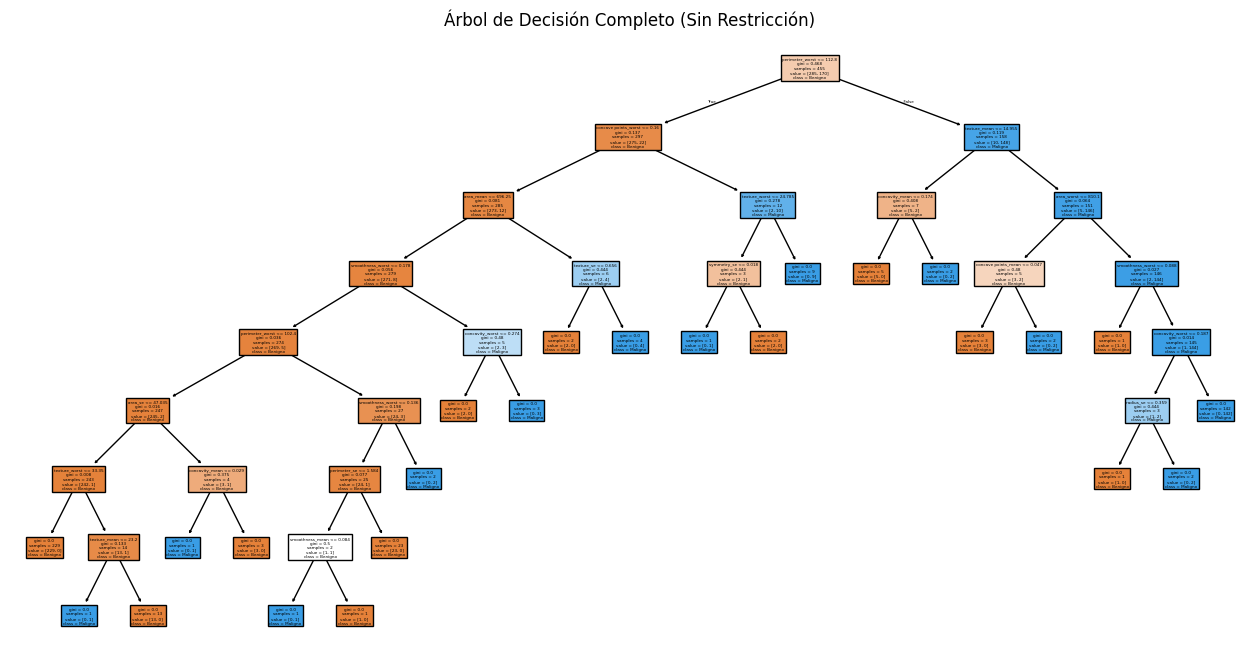

--- Métricas resumen del Árbol Sin Restricción ---
Accuracy:  0.9298245614035088
Precision: 0.9047619047619048
Recall:    0.9047619047619048
F1-Score:  0.9047619047619048
ROC-AUC:   0.9246031746031745


In [ ]:
#Dibujamos el árbol libre para ver cómo se estructuró
plt.figure(figsize=(16, 8))
plot_tree(tree_full, feature_names=X.columns, class_names=['Benigno', 'Maligno'], filled=True)
plt.title('Árbol de Decisión Completo (Sin Restricción)')
plt.show()

#Calculamos e interpretamos las métricas para este árbol completo
y_pred_full = tree_full.predict(X_test)
y_prob_full = tree_full.predict_proba(X_test)[:, 1]

print("--- Métricas resumen del Árbol Sin Restricción ---")
print("Accuracy: ", accuracy_score(y_test, y_pred_full))
print("Precision:", precision_score(y_test, y_pred_full))
print("Recall:   ", recall_score(y_test, y_pred_full))
print("F1-Score: ", f1_score(y_test, y_pred_full))
print("ROC-AUC:  ", roc_auc_score(y_test, y_prob_full))

###7: Árbol Podado y Evaluación Final

In [ ]:
# Volvemos a armar el árbol pero limitando su profundidad a 3 (podado)
tree_pruned = DecisionTreeClassifier(max_depth=3, random_state=0)
tree_pruned.fit(X_train, y_train)

#  Evaluamos la exactitud en entrenamiento y prueba
score_train_pruned = tree_pruned.score(X_train, y_train)
score_test_pruned = tree_pruned.score(X_test, y_test)

print(f"Exactitud en Entrenamiento (max_depth=3): {score_train_pruned:.4f}")
print(f"Exactitud en Prueba (max_depth=3): {score_test_pruned:.4f}")

Exactitud en Entrenamiento (max_depth=3): 0.9670
Exactitud en Prueba (max_depth=3): 0.9123


Al limitar la profundidad a 3, el modelo pierde un poco de exactitud perfecta en entrenamiento, pero la brecha entre entrenamiento y prueba se reduce. Esto significa que el modelo es mucho más estable, generaliza mejor con datos nuevos y corrige el overfitting.

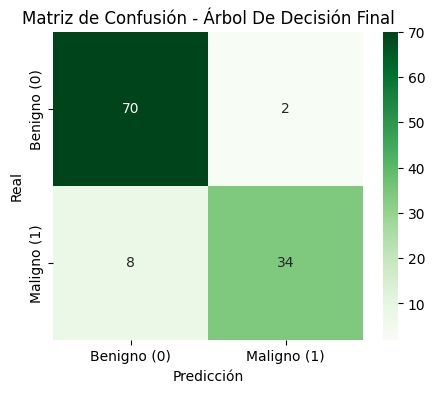

--- Reporte de Clasificación Final (Árbol De Decisión Final) ---
              precision    recall  f1-score   support

 Benigno (0)       0.90      0.97      0.93        72
 Maligno (1)       0.94      0.81      0.87        42

    accuracy                           0.91       114
   macro avg       0.92      0.89      0.90       114
weighted avg       0.91      0.91      0.91       114

Área bajo la curva ROC (ROC-AUC Score): 0.8986


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Matriz de confusión para el árbol podado
y_pred_pruned = tree_pruned.predict(X_test)
cm_pruned = confusion_matrix(y_test, y_pred_pruned)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_pruned, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Benigno (0)', 'Maligno (1)'],
            yticklabels=['Benigno (0)', 'Maligno (1)'])
plt.title('Matriz de Confusión - Árbol De Decisión Final')
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.show()

# 2. Reporte de clasificación
print("--- Reporte de Clasificación Final (Árbol De Decisión Final) ---")
print(classification_report(y_test, y_pred_pruned, target_names=['Benigno (0)', 'Maligno (1)']))

# 3. Cálculo de probabilidades y Métrica ROC-AUC
y_proba_pruned = tree_pruned.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_proba_pruned)

print(f"Área bajo la curva ROC (ROC-AUC Score): {roc_auc:.4f}")



### E. Utilización de Métricas Adecuadas e Interpretación
### Arbol De Decisión

#### 1. Resultados de la Matriz de Confusión
* **Verdaderos Negativos (VN = 70):** 70 casos benignos predichos correctamente.
* **Falsos Positivos (FP = 2):** 2 casos benignos clasificados erróneamente como malignos.
* **Falsos Negativos (FN = 8):** 8 casos malignos no detectados por el modelo (clasificados como benignos).
* **Verdaderos Positivos (VP = 34):** 34 casos malignos detectados correctamente.

#### 2. Reporte de Métricas e Interpretación

#### Casos Beningnos:
* **Precision: 0.90 (90%)** → De las predicciones etiquetadas como benignas, el 90% fueron correctas.
* **Recall / Sensibilidad: 0.97 (97%)** → Métrica principal. El modelo detectó al 97% de los casos reales beningnos.
* **F1-Score (Clase Maligna): 0.93 (93%)** → Excelente balance entre precisión y recall, entre más cercano a 100% mejor balance.


#### Casos Malignos:
* **Precision: 0.94 (94%)** → De las predicciones etiquetadas como malignas, el 94% fueron correctas.
* **Recall / Sensibilidad: 0.81 (81%)** → Métrica principal. El modelo detectó al 81% de las pacientes con cáncer real.
* **F1-Score (Clase Maligna): 0.87 (87%)** → Excelente balance entre precisión y recall, entre más cercano a 100% mejor balance.

###Métricas generales
* **Accuracy Global: 0.91 (91%)** → Clasificación correcta en el 91% del total de pacientes evaluados.
* **Curva ROC-AUC (0.8986)** → lo que es igual una curva del 89.86% y una curva ROC-AUC entre 0.80 y 0.90 Se clasifica como un **desempeño excelente** o muy alto en Machine Learning y diagnóstico médico.

###Conclusión
El modelo de regresión logística que se usó para clasificar (utilizando el parámetro solver = ‘lbfgs’) resultó ser el modelo óptimo para este diagnóstico médico ya que logra una precisión del 100% (sin falsas alarmas de tumor maligno), minimizó al máximo los Falsos Negativos (solo 3 casos omitidos frente a los 8 del Árbol de Decisión) y alcanza un ROC-AUC prácticamente perfecto ($0.9980$ = 99.8%).